# Notebook 05: Model Comparison and Cluster Profiling

**Purpose.** Compare the final K-Means and Ward solutions, describe each segment in original units, and test how much the segments really tell us.

**This is a fair comparison.** Both solutions use the same 50,000 users, the same four standardized features, the same `k`, and the same metrics. Silhouette is reported on all users here, as well as on the fixed 10,000-user subset used during model selection.

In [1]:
import sys
sys.path.append("..")

import json

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score

from src.clustering import assign_to_nearest_centroid, cut_tree, fit_kmeans, full_ward_linkage
from src.data_loader import ensure_output_dirs, load_clean_data, load_config, load_representation, project_path
from src.evaluation import (
    categorical_profile,
    external_association_table,
    internal_metrics,
    make_evaluation_index,
    numeric_profile,
    per_cluster_silhouette,
    size_table,
)
from src.preprocessing import build_numeric_representation
from src.visualization import (
    apply_plot_style,
    plot_contingency,
    plot_external_rates,
    plot_pca_all_segments,
    plot_profile_heatmaps,
    plot_segment_sizes,
    plot_stability,
    save_figure,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)

config = load_config()
ensure_output_dirs(config)
apply_plot_style()

METRICS_DIR = project_path(config["paths"]["metrics_dir"])
PROFILES_DIR = project_path(config["paths"]["profiles_dir"])
SEED = config["random_seed"]
NUMERIC_FEATURES = config["columns"]["representation_a_numeric"]
K_KMEANS = config["kmeans"]["selected_k"]
K_WARD = config["hierarchical"]["selected_k"]
SILHOUETTE_SIZE = config["evaluation"]["silhouette_sample_size"]

users = load_clean_data(config)
representation_a = load_representation(config, "a")
representation_b = load_representation(config, "b")
X = representation_a.to_numpy()

# Join labels on user_id and check nothing was lost or reordered.
assignments = (
    users[["user_id"]]
    .merge(pd.read_csv(PROFILES_DIR / "kmeans_labels.csv"), on="user_id", validate="one_to_one")
    .merge(pd.read_csv(PROFILES_DIR / "cah_labels.csv"), on="user_id", validate="one_to_one")
)
assert len(assignments) == len(users) and (assignments["user_id"] == users["user_id"]).all()
assert (representation_a.index == users["user_id"]).all()

kmeans_labels = assignments["kmeans_label"].to_numpy()
ward_labels = assignments["ward_label"].to_numpy()
kmeans_segments = assignments["kmeans_segment"]
ward_segments = assignments["ward_segment"]
silhouette_index = make_evaluation_index(len(X), SILHOUETTE_SIZE, SEED)
ALGORITHMS = {"K-Means": kmeans_segments, "Ward (CAH)": ward_segments}
assignments.to_csv(PROFILES_DIR / "final_segment_assignments.csv", index=False)
print("Labels aligned for", len(assignments), "users")

Labels aligned for 50000 users


## A. Evaluation metrics

- **Silhouette:** higher is generally better (from -1 to 1).
- **Davies-Bouldin:** lower is generally better.
- **Calinski-Harabasz:** higher is generally better.

These metrics reward compact, separated, round clusters, so they can favour different structures and they do not prove that clusters are meaningful. That is why the table also shows what each method achieves on **permuted data**, which has no joint structure, using the reference runs from Notebooks 03 and 04.

In [2]:
def reference_row(file_name, k, metric):
    reference = pd.read_csv(METRICS_DIR / file_name)
    values = reference.loc[reference["k"] == k, metric]
    return values.mean(), values.min(), values.max()

rows = []
for algorithm, labels, k, reference_file in [
    ("K-Means", kmeans_labels, K_KMEANS, "kmeans_reference_scan.csv"),
    ("Ward (CAH)", ward_labels, K_WARD, "cah_ward_reference_scan.csv"),
]:
    metrics_all = internal_metrics(X, labels)
    metrics_subset = internal_metrics(X, labels, silhouette_index)
    row = {
        "algorithm": algorithm,
        "k": k,
        "silhouette_all_users": metrics_all["silhouette"],
        "silhouette_10k_subset": metrics_subset["silhouette"],
        "davies_bouldin": metrics_all["davies_bouldin"],
        "calinski_harabasz": metrics_all["calinski_harabasz"],
        "smallest_cluster_share": metrics_all["smallest_cluster_share"],
        "largest_cluster_share": metrics_all["largest_cluster_share"],
    }
    for metric, column in [("silhouette", "silhouette_10k_subset"), ("davies_bouldin", "davies_bouldin"), ("calinski_harabasz", "calinski_harabasz")]:
        mean, low, high = reference_row(reference_file, k, metric)
        row[f"reference_{metric}_mean"] = mean
        row[f"reference_{metric}_min"] = low
        row[f"reference_{metric}_max"] = high
    rows.append(row)

final_comparison = pd.DataFrame(rows)
final_comparison.to_csv(METRICS_DIR / "final_model_comparison.csv", index=False)
final_comparison.set_index("algorithm").T.round(4)

algorithm,K-Means,Ward (CAH)
k,5.0000,5.0000
silhouette_all_users,0.1858,0.1034
silhouette_10k_subset,0.1844,0.1037
davies_bouldin,1.3209,1.6308
calinski_harabasz,10674.5085,7238.2479
smallest_cluster_share,0.1622,0.1328
largest_cluster_share,0.2294,0.2876
reference_silhouette_mean,0.1852,0.1099
reference_silhouette_min,0.1834,0.1016
reference_silhouette_max,0.1884,0.1219


### Does the real data ever beat the reference?

For each `k` and each metric, we count whether the real value falls inside the range seen across the 10 permuted datasets, beats all of them, or is worse than all of them. "Beats" takes the direction of each metric into account.

In [3]:
def classify_against_reference(file_name, algorithm):
    table = pd.read_csv(METRICS_DIR / file_name)
    lower_is_better = table["metric"] == "davies_bouldin"
    above = table["real"] > table["reference_max"]
    below = table["real"] < table["reference_min"]
    table["position"] = "Inside reference range"
    table.loc[(above & ~lower_is_better) | (below & lower_is_better), "position"] = "Better than all references"
    table.loc[(below & ~lower_is_better) | (above & lower_is_better), "position"] = "Worse than all references"
    table["algorithm"] = algorithm
    return table

reference_position = pd.concat(
    [
        classify_against_reference("kmeans_vs_reference.csv", "K-Means"),
        classify_against_reference("cah_ward_vs_reference.csv", "Ward (CAH)"),
    ]
)
reference_position.to_csv(METRICS_DIR / "reference_position_by_k.csv", index=False)
display(pd.crosstab([reference_position["algorithm"], reference_position["metric"]], reference_position["position"]))
print("Absolute percent difference from the reference mean, per algorithm:")
display(reference_position.groupby("algorithm")["percent_difference_from_reference"].apply(lambda s: s.abs().describe()[["mean", "max"]]).unstack().round(2))
print("Combinations that beat every reference:")
display(reference_position.loc[reference_position["position"] == "Better than all references", ["algorithm", "k", "metric", "real", "reference_min", "reference_max"]].round(3))

position                      Better than all references  Inside reference range  Worse than all references
algorithm  metric                                                                                          
K-Means    calinski_harabasz                           0                       9                          0
           davies_bouldin                              2                       6                          1
           silhouette                                  0                       8                          1
Ward (CAH) calinski_harabasz                           0                       7                          2
           davies_bouldin                              0                       8                          1
           silhouette                                  0                       8                          1

Absolute percent difference from the reference mean, per algorithm:


,mean,max
algorithm,,
K-Means,0.33,1.61
Ward (CAH),5.61,18.89


Combinations that beat every reference:


,algorithm,k,metric,real,reference_min,reference_max
22,K-Means,9,davies_bouldin,1.313,1.313,1.352
25,K-Means,10,davies_bouldin,1.297,1.300,1.314


**K-Means scores better than Ward on all three metrics** (Silhouette on all users 0.186 against 0.103, Davies-Bouldin 1.321 against 1.631, Calinski-Harabasz 10,675 against 7,238). This is not a surprise: K-Means directly optimizes within-cluster variance, while Ward's early merges are never revisited.

**Neither beats the structureless reference.** Across all 54 combinations of algorithm, `k` and metric:

- 46 are inside the reference range;
- 2 are better than all references, both for K-Means Davies-Bouldin at `k = 9` and `k = 10`, by tiny margins;
- 6 are worse than all references.

If the real data were simply one more draw of the same kind as the references, it would fall outside the range of 10 reference values about 2 times in 11, or around 10 of 54. We observed 8, in line with chance. Results across `k` are related, so this is a rough guide and not a formal test, but the overall message is clear.

The mean absolute difference from the reference is small for K-Means (0.33%) and larger for Ward (5.61%), but Ward's reference results themselves vary widely, and Ward's real values are mostly slightly *below* its reference mean.

## B. Cluster sizes

K-Means         Ward (CAH)        
                      users percent      users percent
segment                                               
Light Listeners     11468.0   22.94     7248.0   14.50
Heavy Listeners     11193.0   22.39        NaN     NaN
Playlist Builders    9673.0   19.35     6642.0   13.28
Frequent Skippers    9554.0   19.11    13603.0   27.21
Low-Rating Users     8112.0   16.22     8125.0   16.25
Low-Skip Listeners      NaN     NaN    14382.0   28.76

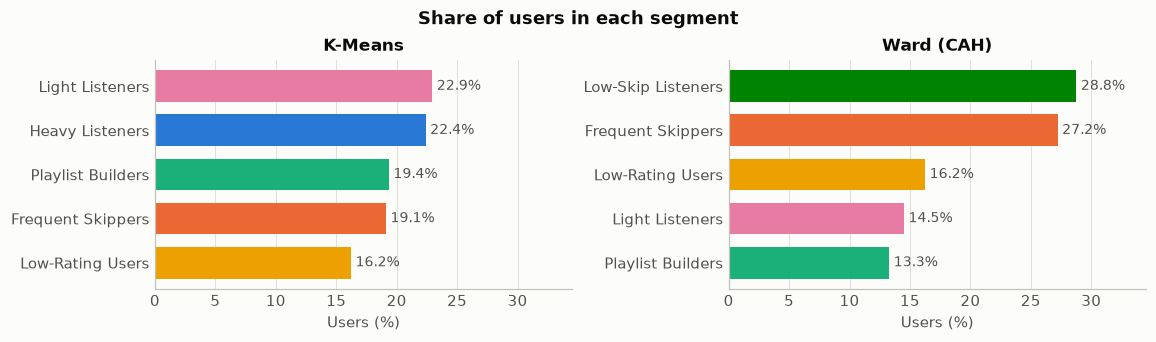

In [4]:
sizes = {algorithm: size_table(segments) for algorithm, segments in ALGORITHMS.items()}
fig = plot_segment_sizes(sizes, "Share of users in each segment")
save_figure(fig, "comparison_segment_sizes", config)
display(pd.concat(sizes, axis=1))

## C. Cluster profiles in original units

**Interpretation rule:** standardized values measure distance from the average user in standard deviations, and are never read as hours or playlists. The heatmap uses them for **color only**, while the numbers printed in each cell are means in the **original units**.

Average across all users: {'avg_listening_hours_per_week': 9.99, 'playlists_created': 8.0, 'avg_skips_per_day': 10.03, 'music_suggestion_rating_1_to_5': 3.64}


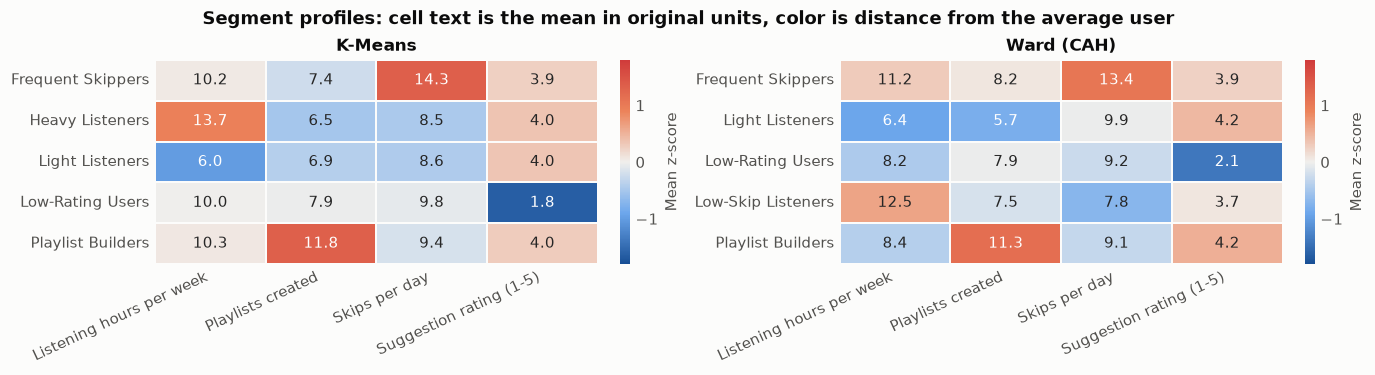

In [5]:
overall_mean = users[NUMERIC_FEATURES].mean()
z_profiles, unit_profiles = {}, {}
for algorithm, segments in ALGORITHMS.items():
    z_profiles[algorithm] = representation_a.reset_index(drop=True).groupby(segments.values).mean()
    unit_profiles[algorithm] = users.groupby(segments.values)[NUMERIC_FEATURES].mean()

fig = plot_profile_heatmaps(z_profiles, unit_profiles, "Segment profiles: cell text is the mean in original units, color is distance from the average user")
save_figure(fig, "comparison_profile_heatmaps", config)
print("Average across all users:", overall_mean.round(2).to_dict())

In [6]:
profile_columns = NUMERIC_FEATURES + ["age", "tenure_months", "months_inactive"]
for algorithm, segments in ALGORITHMS.items():
    profile = numeric_profile(users, segments, profile_columns)
    median_ratio = users.groupby(segments)["skips_per_listening_hour"].median().round(2)
    file_name = algorithm.split(" ")[0].lower().replace("-", "")
    profile.to_csv(PROFILES_DIR / f"{file_name}_numeric_profile.csv")
    z_profiles[algorithm].round(3).to_csv(PROFILES_DIR / f"{file_name}_zscore_profile.csv")
    print(algorithm)
    display(profile)
    print("Median skips per listening hour (descriptive only):", median_ratio.to_dict())

K-Means


avg_listening_hours_per_week        playlists_created        avg_skips_per_day        music_suggestion_rating_1_to_5           age         \
                                          mean median              mean median              mean median                           mean median   mean median   
segment                                                                                                                                                       
Frequent Skippers                        10.17  10.10              7.36    7.0             14.28   14.0                           3.93    4.0  37.99   38.0   
Heavy Listeners                          13.68  13.30              6.53    7.0              8.52    9.0                           4.04    4.0  37.88   38.0   
Light Listeners                           6.02   6.40              6.87    7.0              8.61    9.0                           4.03    4.0  38.15   38.0   
Low-Rating Users                          9.96   9.96              7.89    8.0              9.79   10.0                           1.83    2.0  38.06   38.0   
Playlist Builders                        10.27  10.23             11.78   11.0              9.45   10.0                           3.97    4.0  37.98   38.0   

                  tenure_months        months_inactive         
                           mean median            mean median  
segment                                                        
Frequent Skippers         49.18  49.62            1.54    1.0  
Heavy Listeners           48.83  48.65            1.53    1.0  
Light Listeners           48.92  48.92            1.55    1.0  
Low-Rating Users          48.88  48.87            1.53    1.0  
Playlist Builders         48.76  48.65            1.52    1.0

Median skips per listening hour (descriptive only): {'Frequent Skippers': 9.56, 'Heavy Listeners': 4.51, 'Light Listeners': 9.33, 'Low-Rating Users': 6.8, 'Playlist Builders': 6.42}
Ward (CAH)


avg_listening_hours_per_week        playlists_created        avg_skips_per_day        music_suggestion_rating_1_to_5           age         \
                                           mean median              mean median              mean median                           mean median   mean median   
segment                                                                                                                                                        
Frequent Skippers                         11.17  11.17              8.21    8.0             13.41   13.0                           3.91    4.0  37.97   38.0   
Light Listeners                            6.39   6.39              5.71    5.0              9.92   10.0                           4.16    4.0  38.10   38.0   
Low-Rating Users                           8.15   8.09              7.89    8.0              9.20    9.0                           2.11    2.0  37.97   38.0   
Low-Skip Listeners                        12.46  12.26              7.51    7.0              7.79    8.0                           3.73    4.0  38.05   38.0   
Playlist Builders                          8.41   8.70             11.29   11.0              9.07    9.0                           4.23    4.0  37.97   38.0   

                   tenure_months        months_inactive         
                            mean median            mean median  
segment                                                         
Frequent Skippers          49.37  49.70            1.53    1.0  
Light Listeners            48.53  48.41            1.53    1.0  
Low-Rating Users           48.88  48.92            1.53    1.0  
Low-Skip Listeners         48.76  48.60            1.53    1.0  
Playlist Builders          48.74  48.72            1.55    1.0

Median skips per listening hour (descriptive only): {'Frequent Skippers': 8.52, 'Light Listeners': 10.41, 'Low-Rating Users': 7.68, 'Low-Skip Listeners': 4.44, 'Playlist Builders': 7.45}


## D. The evidence behind each segment name

Names came from a mechanical rule in Notebooks 03 and 04: the feature with the largest absolute mean z-score and its direction. This table lets you check each name against the numbers. **The names describe position on the input features only**: "Low-Rating Users" rate music suggestions low on average, which is not evidence that they are dissatisfied with the whole service or likely to leave.

In [7]:
evidence_rows = []
for algorithm, z_values in z_profiles.items():
    for segment, row in z_values.iterrows():
        ordered = row.abs().sort_values(ascending=False)
        strongest, second = ordered.index[0], ordered.index[1]
        evidence_rows.append(
            {
                "algorithm": algorithm,
                "segment": segment,
                "defining_feature": strongest,
                "segment_mean": round(unit_profiles[algorithm].loc[segment, strongest], 2),
                "all_users_mean": round(overall_mean[strongest], 2),
                "z_score": round(row[strongest], 2),
                "second_feature": second,
                "second_z_score": round(row[second], 2),
            }
        )
segment_evidence = pd.DataFrame(evidence_rows)
segment_evidence.to_csv(PROFILES_DIR / "segment_name_evidence.csv", index=False)
pd.set_option("display.max_colwidth", 40)
segment_evidence

,algorithm,segment,defining_feature,segment_mean,all_users_mean,z_score,second_feature,second_z_score
0,K-Means,Frequent Skippers,avg_skips_per_day,14.28,10.03,1.34,music_suggestion_rating_1_to_5,0.26
1,K-Means,Heavy Listeners,avg_listening_hours_per_week,13.68,9.99,0.93,playlists_created,-0.52
2,K-Means,Light Listeners,avg_listening_hours_per_week,6.02,9.99,-1.00,avg_skips_per_day,-0.45
3,K-Means,Low-Rating Users,music_suggestion_rating_1_to_5,1.83,3.64,-1.63,avg_skips_per_day,-0.07
4,K-Means,Playlist Builders,playlists_created,11.78,8.00,1.33,music_suggestion_rating_1_to_5,0.29
5,Ward (CAH),Frequent Skippers,avg_skips_per_day,13.41,10.03,1.07,avg_listening_hours_per_week,0.30
6,Ward (CAH),Light Listeners,avg_listening_hours_per_week,6.39,9.99,-0.91,playlists_created,-0.81
7,Ward (CAH),Low-Rating Users,music_suggestion_rating_1_to_5,2.11,3.64,-1.38,avg_listening_hours_per_week,-0.46
8,Ward (CAH),Low-Skip Listeners,avg_skips_per_day,7.79,10.03,-0.71,avg_listening_hours_per_week,0.62
9,Ward (CAH),Playlist Builders,playlists_created,11.29,8.00,1.16,music_suggestion_rating_1_to_5,0.53


**Do the names hold up?** As descriptions of position on these features, yes:

| Segment | K-Means evidence | Ward evidence |
|---|---|---|
| **Frequent Skippers** | 14.28 skips per day vs 10.03 overall (z = 1.34) | 13.41 skips (z = 1.07) |
| **Heavy Listeners** | 13.68 hours per week vs 9.99 overall (z = 0.93) | Not a Ward segment |
| **Light Listeners** | 6.02 hours (z = -1.00) | 6.39 hours (z = -0.91), plus few playlists: 5.71 vs 8.00 (z = -0.81) |
| **Low-Rating Users** | Rating 1.83 vs 3.64 overall (z = -1.63) | Rating 2.11 (z = -1.38) |
| **Playlist Builders** | 11.78 playlists vs 8.00 overall (z = 1.33) | 11.29 playlists (z = 1.16) |
| **Low-Skip Listeners** | Not a K-Means segment | 7.79 skips (z = -0.71), plus above-average hours: 12.46 (z = 0.62) |

**Important cautions.**

- Being the same name does not mean the same users. Section F measures the overlap.
- K-Means segments are each defined mainly by one feature. Ward segments are less pure: for example, Low-Skip Listeners are defined by two features at once.
- These differences are guaranteed by construction, because clustering works directly on these features. They are not independent findings.

### How well separated is each segment?

For each segment we report the mean silhouette and the share of its users with a negative silhouette, meaning they are closer to a *different* segment than to their own on average.

In [8]:
silhouette_rows = []
for algorithm, labels, column in [("K-Means", kmeans_labels, "kmeans_segment"), ("Ward (CAH)", ward_labels, "ward_segment")]:
    names = dict(zip(assignments[column.replace("segment", "label")], assignments[column]))
    table = per_cluster_silhouette(X, labels, silhouette_index, names)
    table.insert(0, "algorithm", algorithm)
    silhouette_rows.append(table)
segment_silhouette = pd.concat(silhouette_rows, ignore_index=True)
segment_silhouette.to_csv(METRICS_DIR / "segment_silhouette.csv", index=False)
segment_silhouette.round(3)

,algorithm,segment,mean_silhouette,share_negative
0,K-Means,Heavy Listeners,0.195,0.008
1,K-Means,Frequent Skippers,0.173,0.043
2,K-Means,Playlist Builders,0.172,0.048
3,K-Means,Low-Rating Users,0.173,0.101
4,K-Means,Light Listeners,0.203,0.000
5,Ward (CAH),Frequent Skippers,0.016,0.458
6,Ward (CAH),Low-Rating Users,0.155,0.142
7,Ward (CAH),Light Listeners,0.183,0.143
8,Ward (CAH),Playlist Builders,0.177,0.154
9,Ward (CAH),Low-Skip Listeners,0.084,0.294


**Separation is weak everywhere, especially for Ward.** All K-Means segments have mean silhouettes from 0.172 to 0.203, with at most about 10% of users on the wrong side (Low-Rating Users, 10.1%). Ward's Frequent Skippers segment is close to meaningless as a separated group: mean silhouette 0.016, with **45.8% of its users closer to another segment**. Ward's Low-Skip Listeners also have 29.4% negative values.

## E. Do segments differ on anything else?

So far, segments differ on the features used to create them. That is guaranteed by construction, so it proves nothing. The real test of a useful segmentation is whether segments also differ on **variables the algorithm never saw**. This is the proper use of the outcome columns: description after clustering, not selection of the model.

We report effect sizes (eta squared and Cramér's V, where 0 means no association) because with 50,000 users even trivial differences can reach statistical significance. With 26 tests, we use a Bonferroni threshold of 0.05 / 26 to limit false alarms.

In [9]:
external_numeric = ["age", "tenure_months", "months_inactive"]
external_categorical = config["columns"]["interpretation_categorical"]

association_tables = []
for algorithm, segments in ALGORITHMS.items():
    table = external_association_table(users, segments.to_numpy(), external_numeric, external_categorical)
    table.insert(0, "algorithm", algorithm)
    association_tables.append(table)
associations = pd.concat(association_tables, ignore_index=True)
bonferroni_threshold = 0.05 / len(associations)
associations["significant_after_bonferroni"] = associations["p_value"] < bonferroni_threshold
associations.to_csv(METRICS_DIR / "external_associations.csv", index=False)

print(f"Tests: {len(associations)}. Bonferroni threshold: {bonferroni_threshold:.5f}")
print(f"Largest effect size: {associations['effect_size'].max():.4f}")
print(f"Significant after correction: {int(associations['significant_after_bonferroni'].sum())}")
associations.pivot(index="variable", columns="algorithm", values=["effect_size", "p_value"]).round(4)

Tests: 26. Bonferroni threshold: 0.00192
Largest effect size: 0.0145
Significant after correction: 0


effect_size            p_value           
algorithm                         K-Means Ward (CAH) K-Means Ward (CAH)
variable                                                               
ad_conversion_to_subscription      0.0056     0.0091  0.8158     0.3867
ad_interaction                     0.0068     0.0078  0.6793     0.5504
age                                0.0001     0.0000  0.6069     0.9404
country                            0.0145     0.0139  0.5489     0.7021
desired_future_feature             0.0108     0.0106  0.2754     0.3239
favorite_genre                     0.0139     0.0133  0.7091     0.8177
inactive_3_months_flag             0.0077     0.0106  0.5645     0.2334
months_inactive                    0.0000     0.0000  0.8186     0.9298
most_liked_feature                 0.0116     0.0132  0.5177     0.1724
primary_device                     0.0097     0.0085  0.2769     0.5601
subscription_status                0.0087     0.0057  0.4345     0.8043
subscription_type                  0.0077     0.0099  0.7453     0.2383
tenure_months                      0.0000     0.0001  0.8742     0.2338

Status: Inactive  Inactive 3+ months  Converted from an ad  On a paid plan
K-Means    Frequent Skippers              15.73               22.23                  8.70           54.48
           Heavy Listeners                15.38               21.97                  8.42           54.81
           Light Listeners                16.07               22.54                  8.84           55.02
           Low-Rating Users               15.51               21.77                  8.81           55.08
           Playlist Builders              16.19               22.63                  8.78           55.38
Ward (CAH) Frequent Skippers              15.74               22.05                  8.88           54.69
           Light Listeners                15.94               22.24                  8.44           54.77
           Low-Rating Users               15.54               21.98                  9.07           54.68
           Low-Skip Listeners             15.67               22.08                  8.41           54.89
           Playlist Builders              16.23               23.35                  8.81           56.13

All users: {'Status: Inactive': 15.78, 'Inactive 3+ months': 22.25, 'Converted from an ad': 8.7, 'On a paid plan': 54.95}


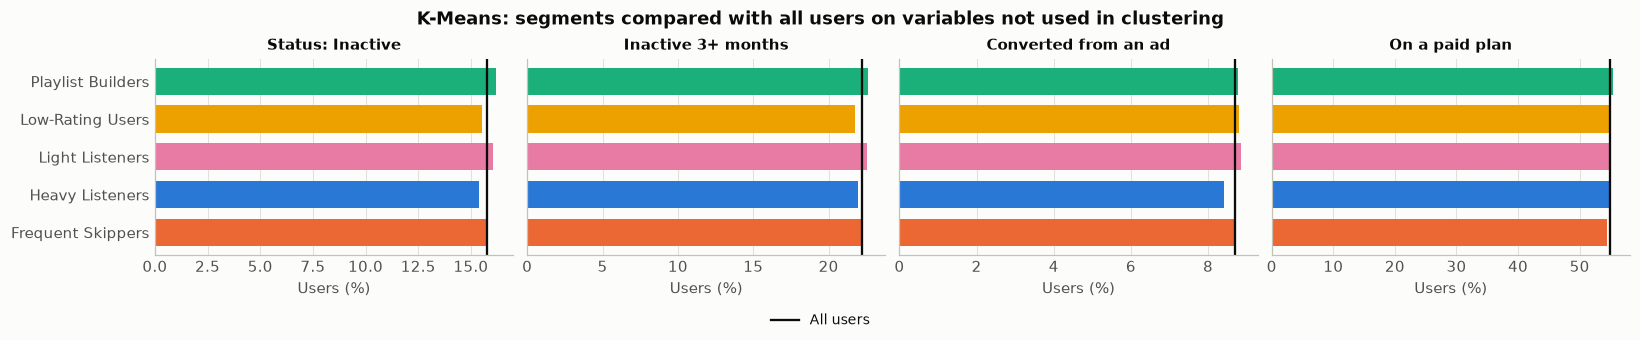

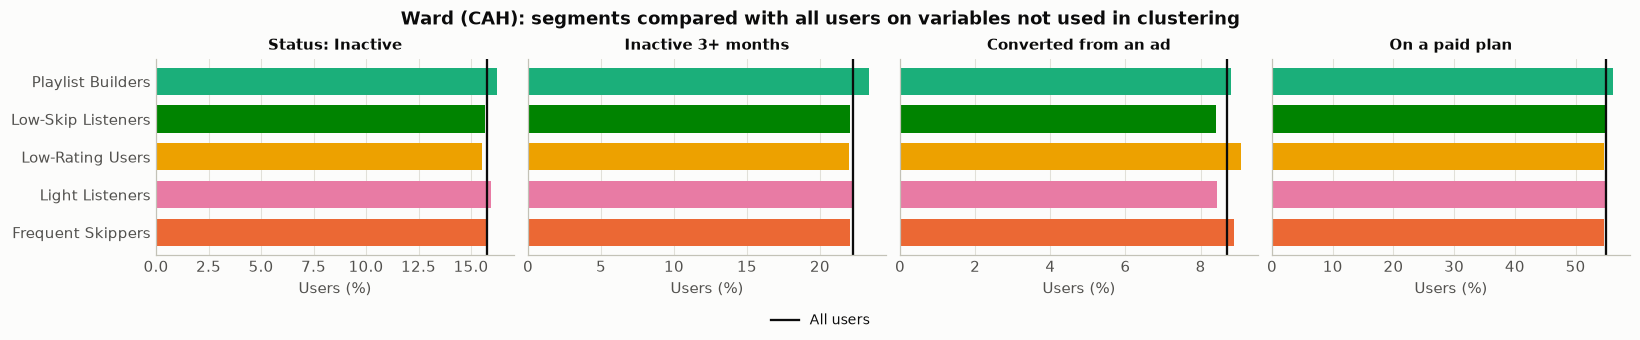

In [10]:
external_flags = pd.DataFrame(
    {
        "Status: Inactive": users["subscription_status"] == "Inactive",
        "Inactive 3+ months": users["inactive_3_months_flag"] == 1,
        "Converted from an ad": users["ad_conversion_to_subscription"] == "Yes",
        "On a paid plan": users["subscription_type"] != "Free",
    }
)
overall_rates = 100 * external_flags.mean()
external_rates = {}
for algorithm, segments in ALGORITHMS.items():
    rates = 100 * external_flags.groupby(segments.values).mean()
    external_rates[algorithm] = rates
    fig = plot_external_rates(rates, overall_rates, f"{algorithm}: segments compared with all users on variables not used in clustering")
    save_figure(fig, f"comparison_external_rates_{algorithm.split(' ')[0].lower().replace('-', '')}", config)
    rates.round(2).to_csv(PROFILES_DIR / f"{algorithm.split(' ')[0].lower().replace('-', '')}_external_rates.csv")
display(pd.concat(external_rates).round(2))
print("All users:", overall_rates.round(2).to_dict())

In [11]:
# Full categorical distributions are saved for reference. Here we show only the largest gap.
gap_rows = []
for algorithm, segments in ALGORITHMS.items():
    short_name = algorithm.split(" ")[0].lower().replace("-", "")
    for column in ["subscription_type", "primary_device", "favorite_genre", "most_liked_feature", "desired_future_feature", "country"]:
        table = categorical_profile(users, segments, column)
        table.to_csv(PROFILES_DIR / f"{short_name}_distribution_{column}.csv")
        gap_rows.append({"algorithm": algorithm, "variable": column, "largest_gap_percentage_points": (table.max() - table.min()).max()})
pd.DataFrame(gap_rows).pivot(index="variable", columns="algorithm", values="largest_gap_percentage_points").round(1)

algorithm,K-Means,Ward (CAH)
variable,,
country,1.3,1.2
desired_future_feature,1.1,2.0
favorite_genre,1.0,1.1
most_liked_feature,1.2,1.4
primary_device,1.4,1.3
subscription_type,1.3,1.8


**Result: segments carry essentially no information about anything outside their own inputs.**

- **Effect sizes are negligible.** The largest of all 26 is Cramér's V = 0.0145 (`country`, K-Means). Eta squared is 0.0001 or less for age, tenure and months inactive.
- **No test is significant,** after correction or even at the uncorrected 5% level (the smallest p-value is 0.17).
- **Rates are nearly flat.** For K-Means, `Inactive` status ranges from 15.38% to 16.19% across segments (15.78% overall). Ad conversion ranges from 8.42% to 8.84% (8.70% overall), and paid plans from 54.48% to 55.38% (54.95% overall). Ward's ranges are similar.
- **Category shares barely move.** The largest gap in any category is 1.4 percentage points for K-Means and 2.0 for Ward.

**What this means.** We **cannot** claim that any segment represents churn risk, dissatisfaction, or subscription conversion. For example, Low-Rating Users are no more likely to be inactive than anyone else. Marketing to a segment based on these variables would have no supporting evidence in this dataset.

## F. Do the algorithms agree?

ARI compares the two partitions while correcting for chance. AMI is a similar measure based on information theory. The table below shows where each K-Means segment's users end up in the Ward solution.

{'adjusted_rand_index': 0.306, 'adjusted_mutual_information': 0.355}
Frequent Skippers: 8,173 users in both versions; overlap (Jaccard) = 0.55
Light Listeners: 5,312 users in both versions; overlap (Jaccard) = 0.40
Low-Rating Users: 5,417 users in both versions; overlap (Jaccard) = 0.50
Playlist Builders: 4,733 users in both versions; overlap (Jaccard) = 0.41


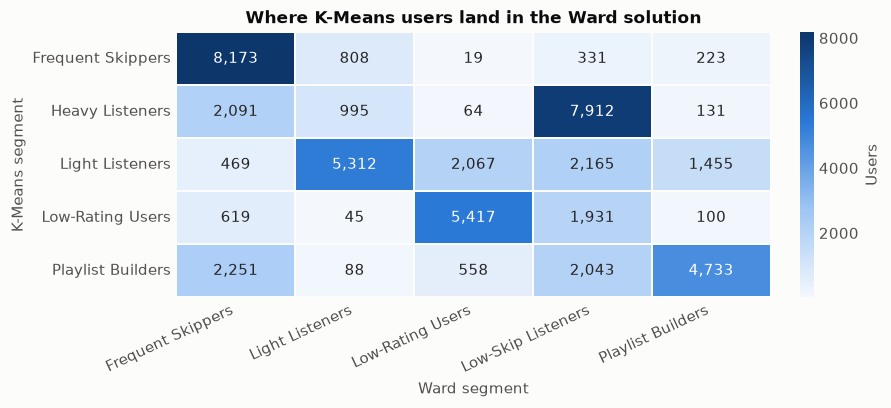

In [12]:
agreement = {
    "adjusted_rand_index": adjusted_rand_score(kmeans_labels, ward_labels),
    "adjusted_mutual_information": adjusted_mutual_info_score(kmeans_labels, ward_labels),
}
print({name: round(value, 3) for name, value in agreement.items()})

contingency = pd.crosstab(kmeans_segments, ward_segments)
contingency.to_csv(PROFILES_DIR / "kmeans_vs_ward_contingency.csv")
fig = plot_contingency(contingency, "Where K-Means users land in the Ward solution")
save_figure(fig, "comparison_kmeans_vs_ward", config)

shared_names = sorted(set(kmeans_segments) & set(ward_segments))
for name in shared_names:
    same = ((kmeans_segments == name) & (ward_segments == name)).sum()
    either = ((kmeans_segments == name) | (ward_segments == name)).sum()
    print(f"{name}: {same:,} users in both versions; overlap (Jaccard) = {same / either:.2f}")

**Result: the two algorithms agree only moderately** (ARI 0.306, AMI 0.355). Same-named segments overlap only partly, with Jaccard values from 0.40 (Light Listeners) to 0.55 (Frequent Skippers). The Frequent Skippers of K-Means are the most consistent: 8,173 of 9,554 (85.5%) also land in Ward's segment of that name. Most K-Means Heavy Listeners (7,912 of 11,193, or 70.7%) land in Ward's Low-Skip Listeners, which shows the two methods describing similar territory with different boundaries.

**Why they differ.** Both minimize variance, but K-Means revises assignments until they settle, while Ward makes greedy merges that are never undone. With no natural boundaries to find, each method's cuts depend on its own mechanics, so there is no shared "true" answer for them to converge on.

## G. Stability side by side

algorithm            K-Means                   Ward (CAH)          
dataset   Permuted reference Real data Permuted reference Real data
k                                                                  
2                      0.933     0.809              0.357     0.272
3                      0.570     0.447              0.283     0.286
4                      0.477     0.447              0.337     0.297
5                      0.765     0.801              0.368     0.350
6                      0.501     0.498              0.342     0.322
7                      0.383     0.384              0.320     0.305
8                      0.340     0.329              0.308     0.304
9                      0.364     0.362              0.299     0.294
10                     0.403     0.374              0.296     0.290

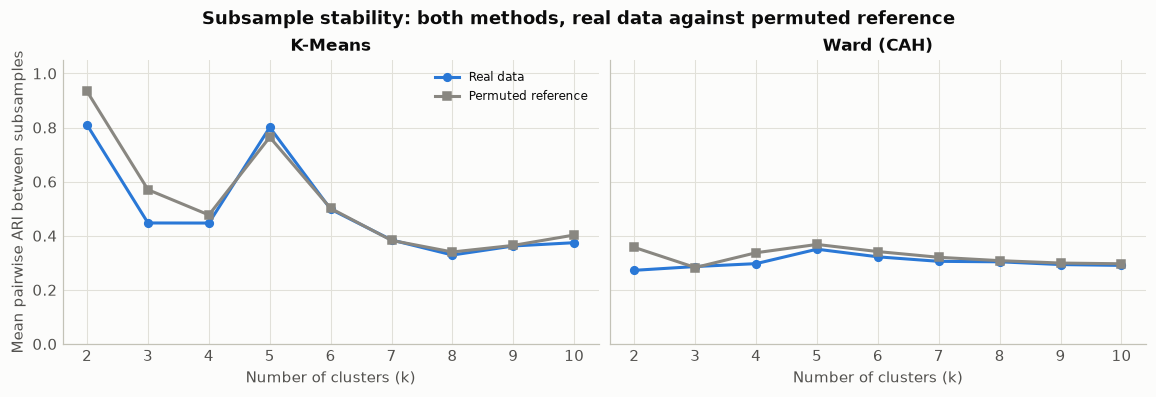

In [13]:
stability = pd.concat(
    [pd.read_csv(METRICS_DIR / "kmeans_subsample_stability.csv"), pd.read_csv(METRICS_DIR / "cah_subsample_stability.csv")],
    ignore_index=True,
)
fig = plot_stability(stability, "Subsample stability: both methods, real data against permuted reference")
save_figure(fig, "comparison_stability", config)
stability.pivot_table(index="k", columns=["algorithm", "dataset"], values="mean_ari").round(3)

**Result.** At `k = 5`, K-Means is far more repeatable than Ward across subsamples (ARI 0.801 against 0.350). If a team needs labels that do not change much when data is refreshed, this favours K-Means. On the other hand, both values are matched on permuted data (0.765 and 0.368), so this describes each method's behaviour rather than the existence of real groups.

## H. Sensitivity to preprocessing and modelling choices

We change one decision at a time, re-fit, and measure how much of the baseline partition survives. An ARI near 1 means that the decision barely matters, and a low ARI means that the segments depend heavily on it. Because the ARI is a comparison across partitions, this is valid even though the feature spaces differ.

In [14]:
def fit_partition(X_input, algorithm, k):
    if algorithm == "K-Means":
        return fit_kmeans(X_input, k, SEED, config["kmeans"]["n_init"], config["kmeans"]["max_iter"]).labels_
    return cut_tree(full_ward_linkage(X_input), k)

robust_matrix, _ = build_numeric_representation(users, NUMERIC_FEATURES, "robust")
X_robust = robust_matrix.to_numpy()
rating_position = NUMERIC_FEATURES.index("music_suggestion_rating_1_to_5")
X_no_rating = np.delete(X, rating_position, axis=1)
X_mixed = representation_b.to_numpy()
active_listeners = users["avg_listening_hours_per_week"].to_numpy() > 0

sensitivity_rows = []
for algorithm, baseline, k in [("K-Means", kmeans_labels, K_KMEANS), ("Ward (CAH)", ward_labels, K_WARD)]:
    scenarios = {
        f"k = {k - 1} instead of {k}": adjusted_rand_score(baseline, fit_partition(X, algorithm, k - 1)),
        f"k = {k + 1} instead of {k}": adjusted_rand_score(baseline, fit_partition(X, algorithm, k + 1)),
        "RobustScaler instead of StandardScaler": adjusted_rand_score(baseline, fit_partition(X_robust, algorithm, k)),
        "Remove the rating feature": adjusted_rand_score(baseline, fit_partition(X_no_rating, algorithm, k)),
        "Exclude the zero-listening-hour users": adjusted_rand_score(baseline[active_listeners], fit_partition(X[active_listeners], algorithm, k)),
        "Representation B (add genre and device)": adjusted_rand_score(baseline, fit_partition(X_mixed, algorithm, k)),
    }
    sensitivity_rows += [{"algorithm": algorithm, "change": change, "ari_with_baseline": ari} for change, ari in scenarios.items()]

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(METRICS_DIR / "sensitivity_analysis.csv", index=False)
sensitivity.pivot(index="change", columns="algorithm", values="ari_with_baseline").round(3)

algorithm,K-Means,Ward (CAH)
change,,
Exclude the zero-listening-hour users,0.926,0.234
Remove the rating feature,0.459,0.156
Representation B (add genre and device),0.963,0.119
RobustScaler instead of StandardScaler,0.462,0.181
k = 4 instead of 5,0.568,0.803
k = 6 instead of 5,0.627,0.890


### Is the preferred `k` also a product of the feature set?

We rescan K-Means after removing the rating. If `k` reflected real groups of users, removing one of four features should not automatically shift the best value.

In [15]:
no_rating_rows = []
for k in range(2, 9):
    labels = fit_kmeans(X_no_rating, k, SEED, config["kmeans"]["n_init"], config["kmeans"]["max_iter"]).labels_
    no_rating_rows.append({"k": k, **internal_metrics(X_no_rating, labels, silhouette_index)})
no_rating_scan = pd.DataFrame(no_rating_rows)
no_rating_scan.to_csv(METRICS_DIR / "kmeans_scan_without_rating.csv", index=False)
no_rating_scan[["k", "silhouette", "davies_bouldin", "calinski_harabasz"]].round(3)

,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.215,1.717,13710.670
1,3,0.218,1.392,14713.297
2,4,0.234,1.151,16179.085
3,5,0.222,1.210,14944.515
4,6,0.223,1.171,14539.223
5,7,0.209,1.160,13811.150
6,8,0.210,1.188,13240.842


**Result: segments depend heavily on analyst choices, especially for Ward.**

| Change | K-Means ARI | Ward ARI | Meaning |
|---|---|---|---|
| RobustScaler | 0.462 | 0.181 | The scaler is a major decision for both |
| Remove rating | 0.459 | 0.156 | The partition depends on which features are chosen |
| Exclude 327 zero-hour users (0.65%) | 0.926 | **0.234** | K-Means barely reacts; removing a handful of users reshapes Ward's tree |
| Representation B | 0.963 | 0.119 | K-Means ignores one-hot columns; Ward follows them |
| `k` - 1 | 0.568 | 0.803 | Ward's nested tree changes less when `k` moves |
| `k` + 1 | 0.627 | 0.890 | Same reason: one more split leaves the rest intact |

The last two rows are the one area where Ward is more robust than K-Means: since its partitions are nested, changing `k` splits or merges only one cluster.

**The preferred `k` moves too.** Without the rating, all three metrics favour `k = 4` for K-Means (Silhouette 0.234, Davies-Bouldin 1.151, Calinski-Harabasz 16,179). A real count of user groups should not be so easily changed by dropping one feature.

**The zero-hour decision.** Keeping these users had little effect on K-Means (ARI 0.926). The much lower Ward value mainly reflects Ward's general instability on this data, as already seen in its subsample results.

## I. The geometry behind the K-Means solution

Each K-Means segment stands out on a single feature. One possible explanation is geometric: to divide one round cloud of points in 4 dimensions into 5 parts, centroids should spread out as evenly as possible. We check this by measuring the distances between centroids, in standardized units. A small coefficient of variation means that they are nearly equally spaced.

In [16]:
geometry_rows = []
for algorithm, labels in [("K-Means", kmeans_labels), ("Ward (CAH)", ward_labels)]:
    centroids = pd.DataFrame(X).groupby(labels).mean().to_numpy()
    distances = pdist(centroids)
    geometry_rows.append(
        {
            "algorithm": algorithm,
            "min_centroid_distance": distances.min(),
            "max_centroid_distance": distances.max(),
            "mean_centroid_distance": distances.mean(),
            "coefficient_of_variation": distances.std() / distances.mean(),
        }
    )
pd.DataFrame(geometry_rows).round(3)

,algorithm,min_centroid_distance,max_centroid_distance,mean_centroid_distance,coefficient_of_variation
0,K-Means,1.935,2.371,2.167,0.066
1,Ward (CAH),1.786,2.252,1.969,0.082


**Result.** K-Means centroids are almost equally spaced: distances run from 1.935 to 2.371 (coefficient of variation 0.066). Ward's are similar (1.786 to 2.252, coefficient of variation 0.082). Evenly spread centroids, each pushed out along a single feature, are what we would expect when one cloud is sliced into five parts.

**This fits the other evidence but does not prove it by itself.** It is also not a universal rule that 4 features give `k = 5`: the pure Gaussian blob in Notebook 03 had its best Silhouette at `k = 8`, not `k = 5`. The feature shapes in this dataset, including the discrete rating, also play a part.

## J. Why do the segments seem to overlap in the PCA picture?

Each user belongs to exactly one segment, yet a scatter plot of all segments seems to show them overlapping. There are two separate reasons, and we measure both:

1. **The picture hides two dimensions.** Clustering happens in four dimensions, but the plot shows only two. Two users can be far apart in the hidden dimensions and still land on the same spot in the picture, just as two planes at different altitudes can cast their shadows on the same point on the ground.
2. **Only K-Means follows the nearest-centroid rule.** Ward builds clusters from a sequence of merges and never reassigns users, so a Ward user can end up closer to the mean of another cluster.

The figures below draw all segments together, with centroid labels. Then we count how often each user's own cluster has the nearest centroid, first in the real 4D space and then in the 2D picture.

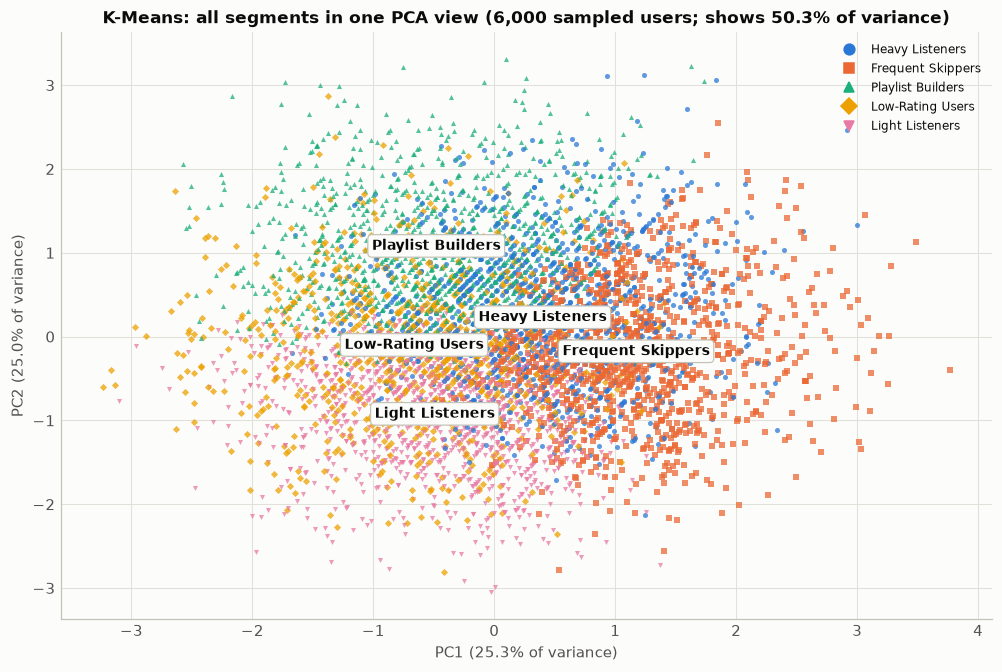

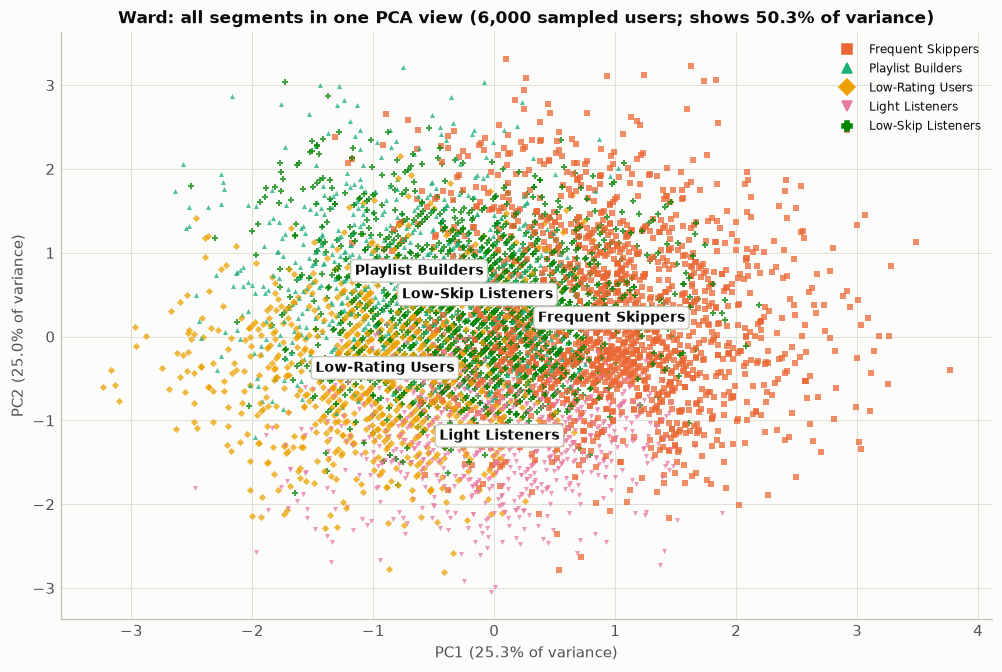

In [17]:
pca = PCA(random_state=SEED).fit(X)
pca_coordinates = pca.transform(X)[:, :2]
variance_shown = pca.explained_variance_ratio_[:2].sum()

fig = plot_pca_all_segments(
    pca_coordinates, kmeans_segments, pca.explained_variance_ratio_,
    f"K-Means: all segments in one PCA view (6,000 sampled users; shows {variance_shown:.1%} of variance)", SEED,
)
save_figure(fig, "kmeans_pca_all_segments", config)

fig = plot_pca_all_segments(
    pca_coordinates, ward_segments, pca.explained_variance_ratio_,
    f"Ward: all segments in one PCA view (6,000 sampled users; shows {variance_shown:.1%} of variance)", SEED,
)
save_figure(fig, "cah_pca_all_segments", config)

In [18]:
def share_nearest_to_own_centroid(points, labels):
    """Share of users whose own cluster has the closest centroid in the given space."""
    return (assign_to_nearest_centroid(points, labels, points) == labels).mean()

overlap_check = pd.DataFrame(
    [
        {
            "algorithm": algorithm,
            "users_with_exactly_one_label": assignments["user_id"].is_unique and bool(pd.notna(labels).all()),
            "nearest_own_centroid_4d_percent": 100 * share_nearest_to_own_centroid(X, labels),
            "nearest_own_centroid_in_2d_picture_percent": 100 * share_nearest_to_own_centroid(pca_coordinates, labels),
        }
        for algorithm, labels in [("K-Means", kmeans_labels), ("Ward (CAH)", ward_labels)]
    ]
)
overlap_check.to_csv(METRICS_DIR / "pca_overlap_check.csv", index=False)
overlap_check.round(2)

,algorithm,users_with_exactly_one_label,nearest_own_centroid_4d_percent,nearest_own_centroid_in_2d_picture_percent
0,K-Means,True,99.93,55.13
1,Ward (CAH),True,74.59,52.11


In [19]:
# K-Means labels are defined against the model's own final centroids, so we check those directly.
final_kmeans = fit_kmeans(X, K_KMEANS, SEED, config["kmeans"]["n_init"], config["kmeans"]["max_iter"])
assert (final_kmeans.labels_ == kmeans_labels).all()
recomputed_means = np.vstack([X[kmeans_labels == label].mean(axis=0) for label in range(K_KMEANS)])
print(f"K-Means users nearest to the model's final centroid: {100 * (final_kmeans.predict(X) == kmeans_labels).mean():.3f}%")
print(f"Largest gap between those centroids and means recomputed from labels: {np.abs(recomputed_means - final_kmeans.cluster_centers_).max():.4f} standard deviations")

# How misleading can the picture be? Take sampled pairs of users who almost touch in 2D.
sample = np.random.default_rng(SEED).choice(len(X), size=4000, replace=False)
picture_distance = pdist(pca_coordinates[sample])
real_distance = pdist(X[sample])
different_cluster = pdist(kmeans_labels[sample].reshape(-1, 1).astype(float)) > 0
almost_touching = picture_distance < 0.05

print(f"Pairs almost touching in the picture (under 0.05 apart): {almost_touching.sum():,}")
print(f"Of those, pairs in different K-Means clusters: {100 * different_cluster[almost_touching].mean():.1f}%")
print(f"Median real 4D distance of those different-cluster pairs: {np.median(real_distance[almost_touching & different_cluster]):.2f}")

K-Means users nearest to the model's final centroid: 100.000%
Largest gap between those centroids and means recomputed from labels: 0.0028 standard deviations
Pairs almost touching in the picture (under 0.05 apart): 4,013
Of those, pairs in different K-Means clusters: 56.8%
Median real 4D distance of those different-cluster pairs: 2.15


**Result.** No user belongs to two clusters. Each has exactly one label, and the apparent overlap has two causes:

| Check | K-Means | Ward (CAH) |
|---|---:|---:|
| Users nearest to their own cluster's centre, in the real 4D space | 100% (of the model's final centroids) | 74.59% |
| Users nearest to their own cluster's centre, in the 2D picture | 55.13% | 52.11% |

- **K-Means follows the nearest-centroid rule exactly.** Recomputing means from the final labels gives 99.93%, only because the algorithm stops once changes become negligible, which leaves the means a tiny distance from its final centroids (at most 0.0028 standard deviations).
- **Ward does not use this rule.** About a quarter of its users are closer to another cluster's mean, because merges are never undone. This is real overlap in the sense that these users sit nearer another group's centre, although each still has only one label.
- **The 2D picture misleads both methods.** Fewer than 6 in 10 users look closest to their own centre, because the plot shows only 50.3% of the variance. Among pairs of sampled users who almost touch in the picture, 56.8% are in different K-Means clusters, with a median real distance of 2.15 standard deviations.

The cloud is also continuous, with no empty space between clusters, so neighbouring users on either side of a boundary can be very similar. Clusters here partition one cloud rather than separating distinct groups.

## K. Computational cost

In [20]:
with open(METRICS_DIR / "kmeans_model_config.json", encoding="utf-8") as file:
    kmeans_record = json.load(file)
with open(METRICS_DIR / "cah_model_config.json", encoding="utf-8") as file:
    ward_record = json.load(file)

cost = pd.DataFrame(
    [
        {
            "algorithm": "K-Means",
            "work": f"{kmeans_record['n_init']} runs at k = {K_KMEANS}, all users",
            "seconds": kmeans_record["fit_seconds_at_selected_k"],
            "changing_k": "Must re-fit",
            "memory": "Grows with n",
        },
        {
            "algorithm": "Ward, vector method (fastcluster)",
            "work": "One full tree, all users",
            "seconds": ward_record["fit_seconds"],
            "changing_k": "Cut the same tree",
            "memory": "Grows with n",
        },
        {
            "algorithm": "Ward, standard SciPy method",
            "work": "Not run on all users",
            "seconds": np.nan,
            "changing_k": "Cut the same tree",
            "memory": "10 GB for the distance matrix alone",
        },
    ]
)
cost.to_csv(METRICS_DIR / "computational_cost.csv", index=False)
cost.round(2)

,algorithm,work,seconds,changing_k,memory
0,K-Means,"20 runs at k = 5, all users",1.56,Must re-fit,Grows with n
1,"Ward, vector method (fastcluster)","One full tree, all users",4.96,Cut the same tree,Grows with n
2,"Ward, standard SciPy method",Not run on all users,NaN,Cut the same tree,10 GB for the distance matrix alone


**Result.** Both are fast on this data, at about 1.6 seconds for K-Means and about 5 seconds for vector-based Ward. Timings will vary by machine, and these are single runs, so small differences should not be over-interpreted.

The more meaningful difference is structural:

- **K-Means** must be re-fitted for every `k`, although it remains light at each step.
- **Ward** builds one tree that can be cut at any `k`. However, it is feasible at this size only with the vector method; the standard method would need 10 GB just for the distance matrix.
- **Among the linkages tested, only Ward and single linkage** have this shortcut. Average and complete linkage remain limited to smaller samples.

## L. Conclusion: comparing the algorithms

| Criterion | K-Means (`k = 5`) | Ward CAH (`k = 5`) | Better |
|---|---|---|---|
| Silhouette, all users | 0.186 | 0.103 | K-Means |
| Davies-Bouldin | 1.321 | 1.631 | K-Means |
| Calinski-Harabasz | 10,675 | 7,238 | K-Means |
| Compared with permuted data | Indistinguishable | Indistinguishable | Neither |
| Cluster sizes | 16.2% to 22.9% | 13.3% to 28.8% | K-Means is more balanced |
| Subsample stability (ARI) | 0.801 | 0.350 | K-Means |
| Interpretability | Each segment mainly defined by one feature | Some segments defined by two features; one barely separated | K-Means |
| Sensitivity to preprocessing | High for scaling and feature choice | Very high, even to removing 0.65% of users | K-Means |
| Sensitivity to `k` | Moderate | Low, because partitions are nested | Ward |
| Computational cost | Light; re-fit per `k` | Light with `fastcluster`; one tree for all `k` | Similar here |

**Recommendation.** If a descriptive segmentation is needed from these features, **use K-Means with `k = 5`**. It is clearer, more balanced and more repeatable.

**The more important finding** is that neither method is supported as discovering natural groups. Scores and stability are matched by data with no joint structure, the partition depends on analyst choices, and segments are unrelated to every variable not used to create them.